 # Task-3 (Week-5)

**Date** :- (02-11-26)

**Dataset** :- 'Admission_Prediction.csv'

**Objective** :- Perform comprehensive cross-validation, including stratified k-fold and nested cross-validation techniques, to ensure robust model generalization and unbiased performance estimation.

In [2]:
# Import Library

import pandas as pd
import numpy as np

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Load the dataset

df = pd.read_csv("Admission_Prediction.csv")

print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Columns:")
print(df.columns.tolist())


Dataset Shape: (1000, 17)


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Year,Application_Date,University_Name,region,Admission Status,Duration_Months,Dropout_Event,Dropout-free survival
0,104,317,104,2,4.5,4.0,8.47,0,0.57,2022,03-01-2022,Indian Institute of Technology Bombay,West,Rejected,36,0,0.536473
1,170,311,99,2,2.5,3.0,7.98,0,0.65,2022,09-01-2022,Indian Institute of Technology Delhi,North,Rejected,18,1,0.973000
2,138,316,100,2,1.5,3.0,8.16,1,0.71,2022,12-01-2022,Indian Institute of Technology Delhi,North,Rejected,33,0,0.597989
3,147,315,105,3,2.0,2.5,8.48,0,0.75,2022,13-01-2022,Indian Institute of Technology Delhi,North,Accepted,33,0,0.597989
4,117,299,102,3,4.0,3.5,8.62,0,0.56,2022,14-01-2022,Indian Institute of Technology Delhi,North,Rejected,28,1,0.734170



Dataset Columns:
['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit', 'Year', 'Application_Date', 'University_Name', 'region', 'Admission Status', 'Duration_Months', 'Dropout_Event', 'Dropout-free survival']


In [6]:
# Prepare features and target

# Remove unnecessary and leakage-prone columns

drop_columns = [
    "Serial No.",
    "Chance of Admit",
    "Application_Date",
    "Duration_Months",
    "Dropout_Event",
    "Dropout-free survival",
    "Survival_Data_Note"
]

df = df.drop(
    columns=drop_columns,
    errors="ignore"
)

# Separate features and target

X = df.drop("Admission Status", axis=1)

y = df["Admission Status"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (1000, 10)
Target Shape: (1000,)

Target Distribution:
Admission Status
Rejected    565
Accepted    435
Name: count, dtype: int64


In [7]:
# Preprocessing

# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()


# Numerical preprocessing

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Categorical preprocessing

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


# Combine preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [8]:
# Create Random Forest model

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

In [9]:
# tratified K-Fold Cross-Validation

# Create Stratified K-Fold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# Perform cross-validation

cv_results = cross_validate(
    rf_pipeline,
    X,
    y,
    cv=skf,
    scoring=["accuracy", "precision_macro",
             "recall_macro", "f1_macro"],
    return_train_score=True,
    n_jobs=-1
)


# Display results

print("Stratified K-Fold Results")

print("Mean Training Accuracy:",
      cv_results["train_accuracy"].mean())

print("Mean Validation Accuracy:",
      cv_results["test_accuracy"].mean())

print("Mean Validation Precision:",
      cv_results["test_precision_macro"].mean())

print("Mean Validation Recall:",
      cv_results["test_recall_macro"].mean())

print("Mean Validation F1 Score:",
      cv_results["test_f1_macro"].mean())

Stratified K-Fold Results
Mean Training Accuracy: 1.0
Mean Validation Accuracy: 0.658
Mean Validation Precision: 0.6557016879356217
Mean Validation Recall: 0.6388973654765537
Mean Validation F1 Score: 0.637719503428547


In [11]:
# : Nested Cross-Validation

# Define hyperparameter combinations
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

In [12]:
# Create outer and inner folds

# Outer cross-validation

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# Inner cross-validation

inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [ ]:
# Perform Nested Cross-Validatio

nested_results = []

best_parameters = []

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y), start=1
):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]

    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]


    # Hyperparameter tuning using inner CV

    grid_search = GridSearchCV(
        estimator=rf_pipeline,
        param_grid=param_grid,
        cv=inner_cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)


    # Best model from inner CV

    best_model = grid_search.best_estimator_


    # Evaluate on outer test fold

    y_pred = best_model.predict(X_test)


    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average="macro",
        zero_division=0
    )


    nested_results.append({
        "Fold": fold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    best_parameters.append(grid_search.best_params_)


# Display fold-wise results

nested_df = pd.DataFrame(nested_results)

display(nested_df)

print("\nNested Cross-Validation Average Results")

print(nested_df.mean(numeric_only=True))

,Fold,Accuracy,Precision,Recall,F1 Score
0,1,0.620,0.610594,0.600244,0.598775
1,2,0.695,0.692857,0.678517,0.680218
2,3,0.625,0.615937,0.609958,0.610177
3,4,0.640,0.632274,0.623233,0.623392
4,5,0.645,0.645992,0.617079,0.611161



Nested Cross-Validation Average Results
Fold         3.000000
Accuracy     0.645000
Precision    0.639531
Recall       0.625806
F1 Score     0.624745
dtype: float64


<Figure size 1000x500 with 0 Axes>

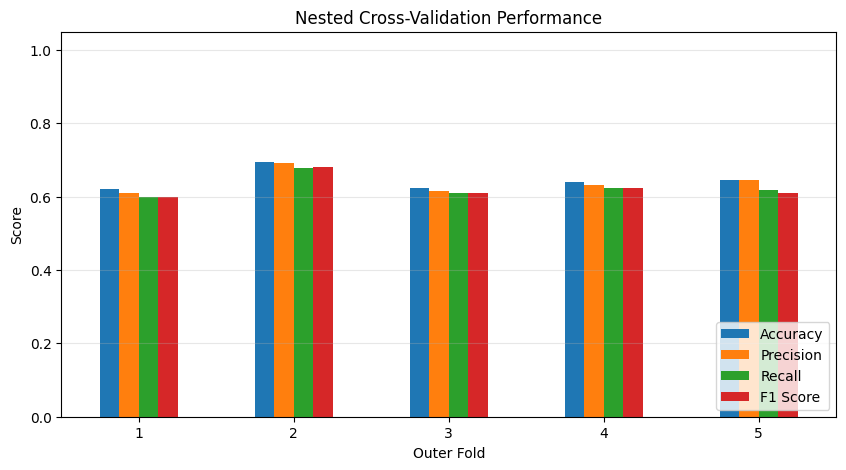

In [14]:
# Visualize Nested Cross-Validation results

plt.figure(figsize=(10, 5))

nested_df.set_index("Fold")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Nested Cross-Validation Performance")
plt.xlabel("Outer Fold")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [15]:
# Display final performance

print("FINAL CROSS-VALIDATION PERFORMANCE")

print("\nStratified K-Fold:")
print("Accuracy:", round(cv_results["test_accuracy"].mean(), 4))
print("F1 Score:", round(cv_results["test_f1_macro"].mean(), 4))

print("\nNested Cross-Validation:")
print("Accuracy:", round(nested_df["Accuracy"].mean(), 4))
print("Precision:", round(nested_df["Precision"].mean(), 4))
print("Recall:", round(nested_df["Recall"].mean(), 4))
print("F1 Score:", round(nested_df["F1 Score"].mean(), 4))

FINAL CROSS-VALIDATION PERFORMANCE

Stratified K-Fold:
Accuracy: 0.658
F1 Score: 0.6377

Nested Cross-Validation:
Accuracy: 0.645
Precision: 0.6395
Recall: 0.6258
F1 Score: 0.6247
